### 선형 회귀
 : Auto MPG 데이터 셋 : 특징 7개으로 연비를 예측하는 회귀 데이터 셋<br><br>

- 본 학습에서는 자동차 무게 하나의 입력값으로 연비을 예측하는 선형회귀 만들기<br>
    `MPG` : 결과 , `weight` : 입력값

In [ ]:
%pip install seaborn

In [1]:
import seaborn as sns
import torch
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
from torch import nn, optim
import numpy as np

# 난수 시드 고정
torch.manual_seed(42)

### Step 1. 데이터 불러오기 및 전처리

In [4]:
data = sns.load_dataset('mpg')

print(data.head())
print(data.shape)
print('결측치 개수 :', data.isnull().sum())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
(398, 9)
결측치 개수 : mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


In [9]:
# 자동차의 무게와 연비만 선택
data = data[['weight', 'mpg']].dropna()

x = torch.tensor(data[['weight']].values, dtype=torch.float32)
y = torch.tensor(data[['mpg']].values, dtype=torch.float32)

# print('입력값 :', x)
print('입력 shape :', x.shape)
# print('정답 :', y)
print('정답 shape :', y.shape)

입력 shape : torch.Size([398, 1])
정답 shape : torch.Size([398, 1])


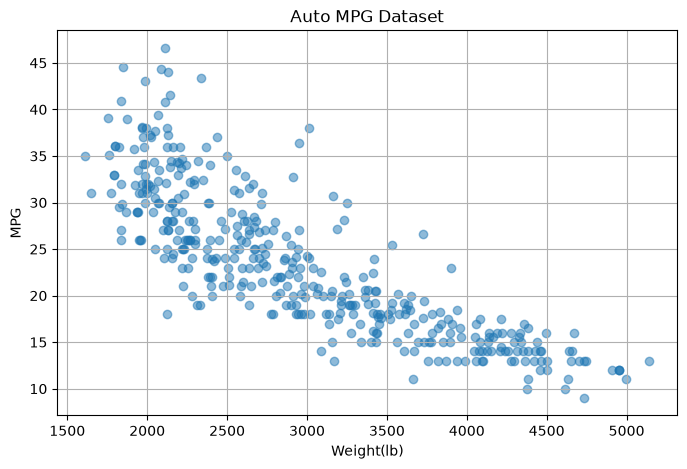

In [10]:
# 그래프 보기
plt.figure(figsize=(8,5))

plt.scatter(x, y, alpha=0.5)

plt.xlabel('Weight(lb)')
plt.ylabel('MPG')
plt.title('Auto MPG Dataset')
plt.grid(True)

In [ ]:
# 학습 데이터와 테스트 데이터 분리(8:2)
indices = torch.randperm(len(x))
train_size = int(len(x) * 0.8)

train_indices = indices[:train_size]
test_indices = indices[train_size:]

x_train = x[train_indices]
x_test = x[test_indices]
y_train = y[train_indices]
y_test = y[test_indices]

# 데이터 표준화
mean = x_train.mean()
std = x_train.std()

x_train_scaled = (x_train - mean) / std
x_test_scaled = (x_test - mean) / std

print('x_train :', x_train_scaled.shape)
print('y_train :', y_train.shape)
print('x_test :', x_test_scaled.shape)
print('y_test :', y_test.shape)

x_train : torch.Size([318, 1])
y_train : torch.Size([318, 1])
x_test : torch.Size([80, 1])
y_test : torch.Size([80, 1])


In [ ]:
# DataLoader 생성
BATCH_SIZE = 32

train_DS = TensorDataset(x_train_scaled, y_train)
test_DS = TensorDataset(x_test_scaled, y_test)

train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle=False)

N = len(train_DL.dataset)
print('학습데이터 개수 :', N)

학습데이터 개수 : 318


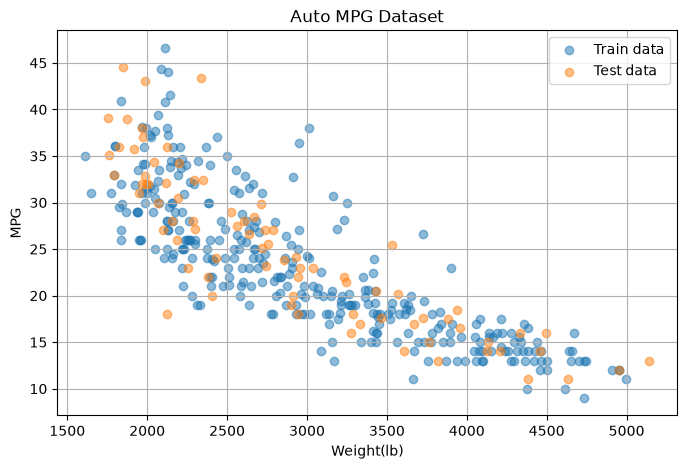

In [18]:
# 그래프로 보기
plt.figure(figsize=(8,5))

plt.scatter(x_train, y_train, alpha=0.5, label='Train data')
plt.scatter(x_test, y_test, alpha=0.5, label='Test data')

plt.xlabel('Weight(lb)')
plt.ylabel('MPG')
plt.title('Auto MPG Dataset')
plt.legend()
plt.grid(True)

### Step 2. 모델 만들기

In [19]:
model = nn.Linear(1,1)

# 임의의 값으로 데이터 5개 출력 확인
b = model(torch.randn(5,1))
print('출력 shape :', b.shape)
print(b)

출력 shape : torch.Size([5, 1])
tensor([[0.3924],
        [0.4343],
        [0.3408],
        [0.3917],
        [0.3655]], grad_fn=<AddmmBackward0>)


### Step 3. 모델 학습 시키기

In [ ]:
LR = 1e-2
EPOCH = 200

optimizer = optim.SGD(model.parameters(), lr=LR)
criterion = nn.MSELoss()

loss_history = []

model.train()
for ep in range(EPOCH):
    rloss = 0

    for x_batch, y_batch in train_DL:

        # inference
        y_hat = model(x_batch)

        # loss
        loss = criterion(y_hat, y_batch)

        # update
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        rloss += loss.item() * x_batch.shape[0]

    loss_e = rloss / N
    loss_history.append(loss_e)

    if ep % 10 == 0:
        print(f'Epoch : {ep+1}, train loss : {loss_e:.4f}')
        print('-'*30)

Epoch : 1, train loss : 491.3685
------------------------------
Epoch : 11, train loss : 26.9911
------------------------------
Epoch : 21, train loss : 18.8293
------------------------------
Epoch : 31, train loss : 18.6876
------------------------------
Epoch : 41, train loss : 18.6786
------------------------------
Epoch : 51, train loss : 18.6872
------------------------------
Epoch : 61, train loss : 18.6752
------------------------------
Epoch : 71, train loss : 18.6797
------------------------------
Epoch : 81, train loss : 18.6933
------------------------------
Epoch : 91, train loss : 18.6899
------------------------------
Epoch : 101, train loss : 18.7033
------------------------------
Epoch : 111, train loss : 18.6982
------------------------------
Epoch : 121, train loss : 18.6830
------------------------------
Epoch : 131, train loss : 18.6875
------------------------------
Epoch : 141, train loss : 18.6811
------------------------------
Epoch : 151, train loss : 18.6777
-

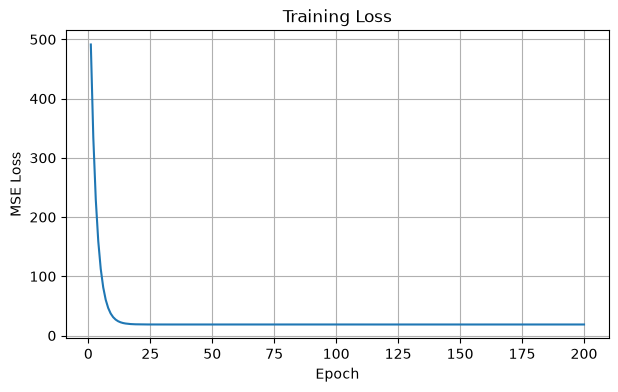

In [22]:
# loss 그래프 그리기
plt.figure(figsize=(7,4))
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss')
plt.grid()

### Step 4. 모델 테스트

In [ ]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test_scaled)

test_loss = criterion(y_pred, y_test).item()  # MSELoss 
test_mae = torch.mean(torch.abs(y_pred - y_test)).item()  # MAELoss
test_rmse = np.sqrt(test_loss)  # MSE에 제곱근을 씌워 원래 데이터와 동일한 단위로 해석

print(f'Test MSE : {test_loss:.3f}')
print(f'Test MAE : {test_mae:.3f} MPG')
print(f'Test RMSE : {test_rmse:.3f} MPG')

Test MSE : 19.554
Test MAE : 3.184 MPG
Test RMSE : 4.422 MPG


### Step 5. 테스트 결과 시각화

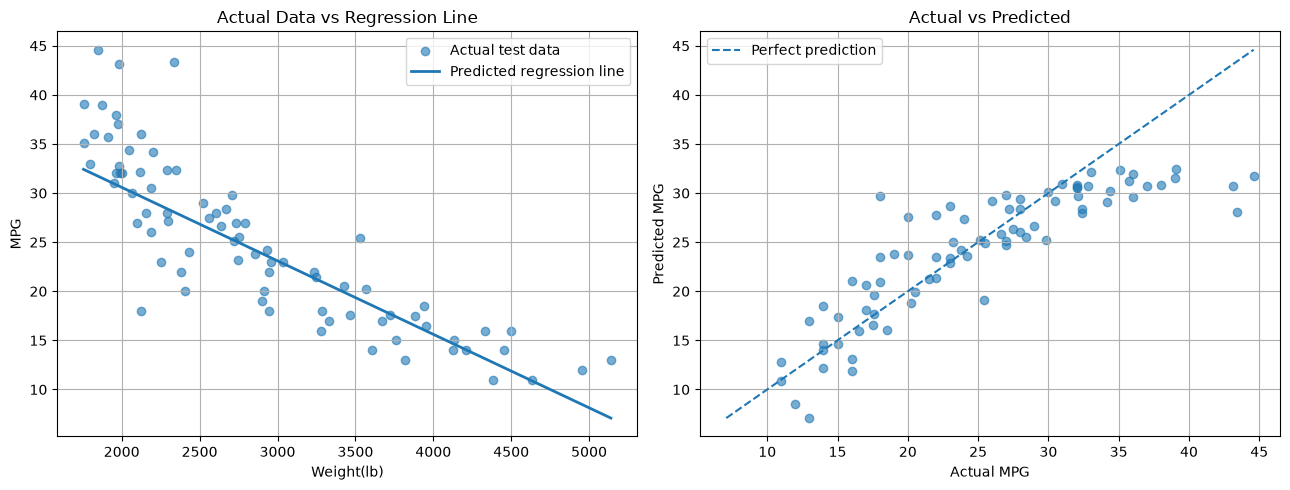

In [27]:
model.eval()
with torch.no_grad():
    y_pred = model(x_test_scaled)

# 무게를 기준을 정렬을 하여 회귀선을 표시
# argsort() : 정렬된 순서에 해당하는 인덱스 반환하는 함수
sort_idx = torch.argsort(x_test.squeeze())
x_test_sorted = x_test[sort_idx]
x_test_scaled_sorted = x_test_scaled[sort_idx]
y_test_sorted = y_test[sort_idx]

with torch.no_grad():
    y_pred_sorted = model(x_test_scaled_sorted)

fig, axes = plt.subplots(1, 2, figsize=(13,5))

# 실제테스트 데이터와 예측 회귀선
axes[0].scatter(x_test.numpy(), y_test.numpy(), 
                alpha = 0.6, label='Actual test data')
axes[0].plot(x_test_sorted.numpy(), y_pred_sorted.numpy(), 
            linewidth=2, label='Predicted regression line')
axes[0].set_xlabel('Weight(lb)')
axes[0].set_ylabel('MPG')
axes[0].set_title('Actual Data vs Regression Line')
axes[0].legend()
axes[0].grid(True)

# 테스트 실제값과 예측값 비교
axes[1].scatter(y_test.numpy(), y_pred.numpy(), alpha=0.6)
min_val = min(y_test.min().item(), y_pred.min().item())
max_val = max(y_test.max().item(), y_pred.max().item())
axes[1].plot([min_val, max_val], [min_val, max_val], 
                linestyle='--', label='Perfect prediction')
axes[1].set_xlabel('Actual MPG')
axes[1].set_ylabel('Predicted MPG')
axes[1].set_title('Actual vs Predicted')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()